# Analise exploratoria - Imoveis da Grande Vitoria

Este notebook faz uma analise exploratoria dos anuncios de venda de imoveis da Grande Vitoria. O foco e entender distribuicoes, diferencas por municipio e variaveis importantes para um futuro modelo de previsao de preco.

## 1. Carregamento e preparacao dos dados

In [31]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 15
plt.rcParams['axes.labelsize'] = 11

DATA_PATH = Path('datasets/vendas_grande_vitoria_clean.csv')
df = pd.read_csv(DATA_PATH)

print(f'Linhas: {df.shape[0]:,}')
print(f'Colunas: {df.shape[1]:,}')
df.head()

Linhas: 17,719
Colunas: 10


,id,price,real_estate_type,municipality,neighbourhood,size,rooms,bathrooms,garage_spaces,has_condominio
0,"1,510,876,553.00","265,000.00",apartamento,cariacica,alto lage,46.00,2,1,1,1
1,"1,355,705,549.00","480,000.00",apartamento,cariacica,alto lage,160.00,3,2,1,1
2,"1,355,701,601.00","480,000.00",apartamento,cariacica,alto lage,166.00,3,2,1,1
3,"1,514,660,394.00","399,000.00",casa,cariacica,alto lage,200.00,3,2,0,0
4,"1,514,636,146.00","350,000.00",casa,cariacica,alto lage,120.00,3,2,1,0


In [32]:
# Padronizacao leve para evitar problemas com tipos vindos do CSV.
data = df.copy()

numeric_cols = [
    'price', 'size', 'rooms', 'bathrooms', 'garage_spaces',
    'condominio', 'iptu', 'image_count', 'price_m2',
    'is_apartment', 'has_condominio', 'has_iptu'
]

for col in numeric_cols:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors='coerce')

if 'date' in data.columns:
    data['date'] = pd.to_datetime(data['date'], errors='coerce')

for col in ['municipality', 'real_estate_type', 'neighbourhood', 'category', 'source']:
    if col in data.columns:
        data[col] = data[col].astype('string').str.strip()

data['city'] = data['municipality'].fillna('Sem cidade')

# Recalcula preco por metro quadrado quando ele estiver ausente, invalido ou infinito.
if {'price', 'size'}.issubset(data.columns):
    computed_price_m2 = data['price'] / data['size'].replace({0: np.nan})
    if 'price_m2' not in data.columns:
        data['price_m2'] = computed_price_m2
    else:
        data['price_m2'] = data['price_m2'].replace([np.inf, -np.inf], np.nan)
        data['price_m2'] = data['price_m2'].fillna(computed_price_m2)

data[['price', 'size', 'price_m2']].describe()

,price,size,price_m2
count,"17,719.00","17,719.00","17,719.00"
mean,"1,044,948.47",108.94,"9,910.62"
std,"776,975.99",68.66,"4,478.78"
min,"120,000.00",15.00,"1,500.00"
25%,"559,000.50",65.00,"6,590.91"
50%,"850,000.00",90.00,"9,250.00"
75%,"1,300,000.00",128.00,"12,500.00"
max,"10,000,000.00",848.00,"34,882.88"


In [33]:
missing = (
    data.isna().sum()
    .to_frame('missing_count')
    .assign(missing_pct=lambda x: 100 * x['missing_count'] / len(data))
    .sort_values('missing_pct', ascending=False)
)

missing.head(20)

,missing_count,missing_pct
id,0,0.00
price,0,0.00
real_estate_type,0,0.00
municipality,0,0.00
neighbourhood,0,0.00
size,0,0.00
rooms,0,0.00
bathrooms,0,0.00
garage_spaces,0,0.00
has_condominio,0,0.00


## 2. Distribuicao de imoveis por cidade

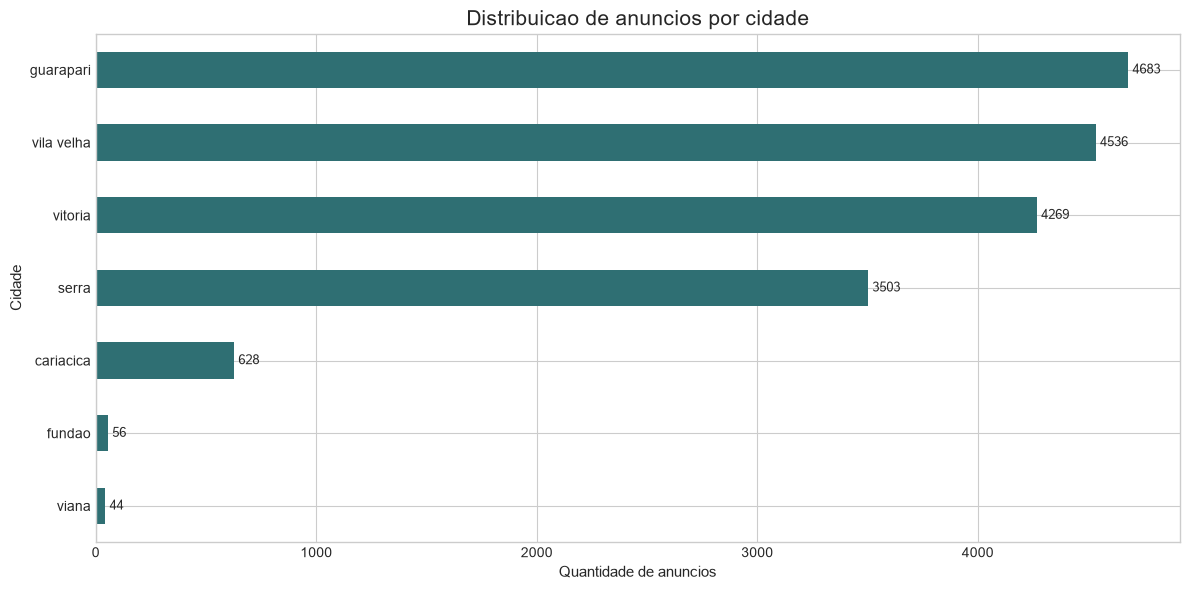

,quantidade
city,
guarapari,4683
vila velha,4536
vitoria,4269
serra,3503
cariacica,628
fundao,56
viana,44


In [34]:
city_counts = data['city'].value_counts()

ax = city_counts.sort_values().plot(kind='barh', color='#2f6f73')
ax.set_title('Distribuicao de anuncios por cidade')
ax.set_xlabel('Quantidade de anuncios')
ax.set_ylabel('Cidade')

for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=9)

plt.tight_layout()
plt.show()

city_counts.to_frame('quantidade')

## 3. Distribuicao do tipo de imovel

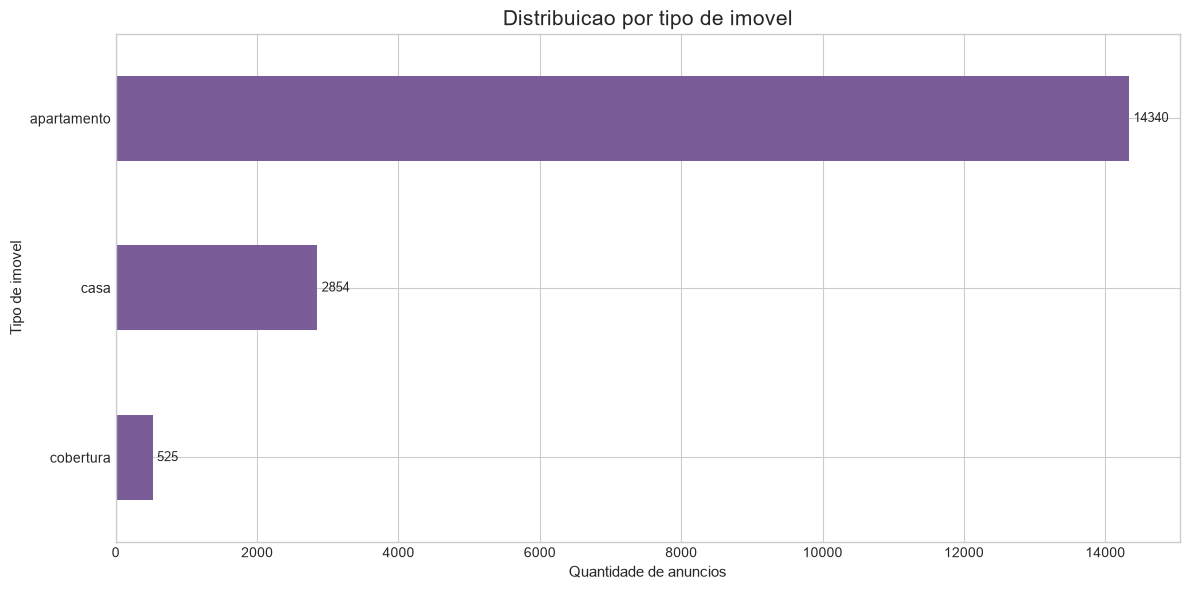

,quantidade
real_estate_type,
apartamento,14340
casa,2854
cobertura,525


In [35]:
type_counts = data['real_estate_type'].fillna('Sem tipo').value_counts()

ax = type_counts.sort_values().plot(kind='barh', color='#7a5c99')
ax.set_title('Distribuicao por tipo de imovel')
ax.set_xlabel('Quantidade de anuncios')
ax.set_ylabel('Tipo de imovel')

for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=9)

plt.tight_layout()
plt.show()

type_counts.to_frame('quantidade')

## 4. Media de preco por cidade

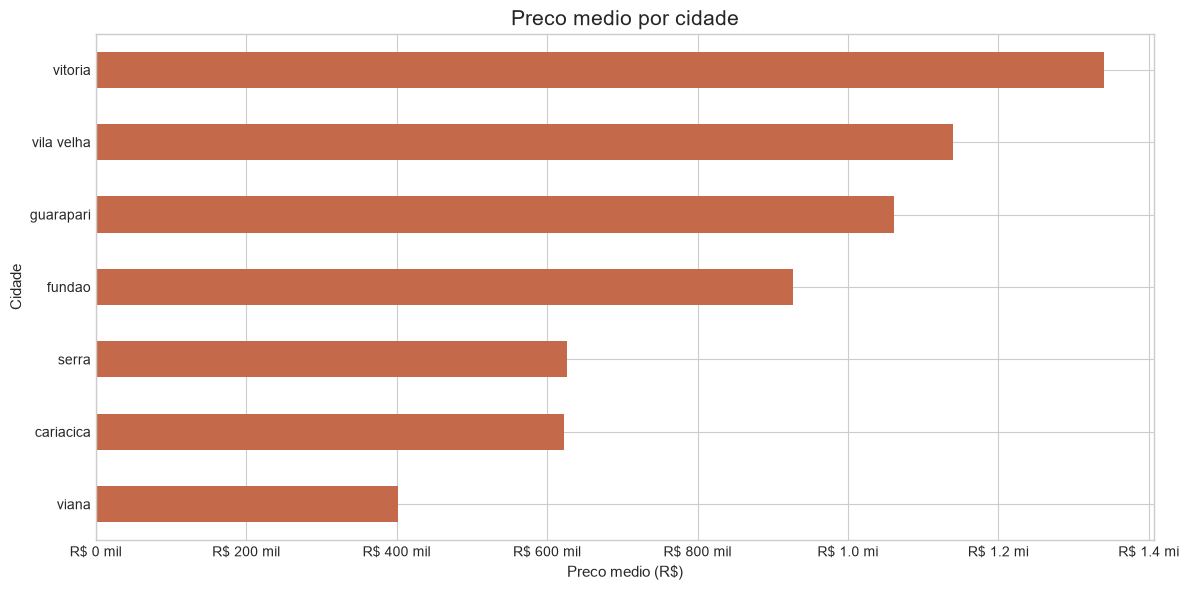

,preco_medio
city,
viana,"401,829.55"
cariacica,"622,103.11"
serra,"626,222.32"
fundao,"926,802.68"
guarapari,"1,060,834.51"
vila velha,"1,140,088.52"
vitoria,"1,340,406.04"


In [36]:
avg_price_city = data.groupby('city')['price'].mean().sort_values()

ax = avg_price_city.plot(kind='barh', color='#c46a4a')
ax.set_title('Preco medio por cidade')
ax.set_xlabel('Preco medio (R$)')
ax.set_ylabel('Cidade')
ax.xaxis.set_major_formatter(lambda x, pos: f'R$ {x/1_000_000:.1f} mi' if x >= 1_000_000 else f'R$ {x/1_000:.0f} mil')

plt.tight_layout()
plt.show()

avg_price_city.to_frame('preco_medio')

## 5. Porcentagem de casas e apartamentos por cidade

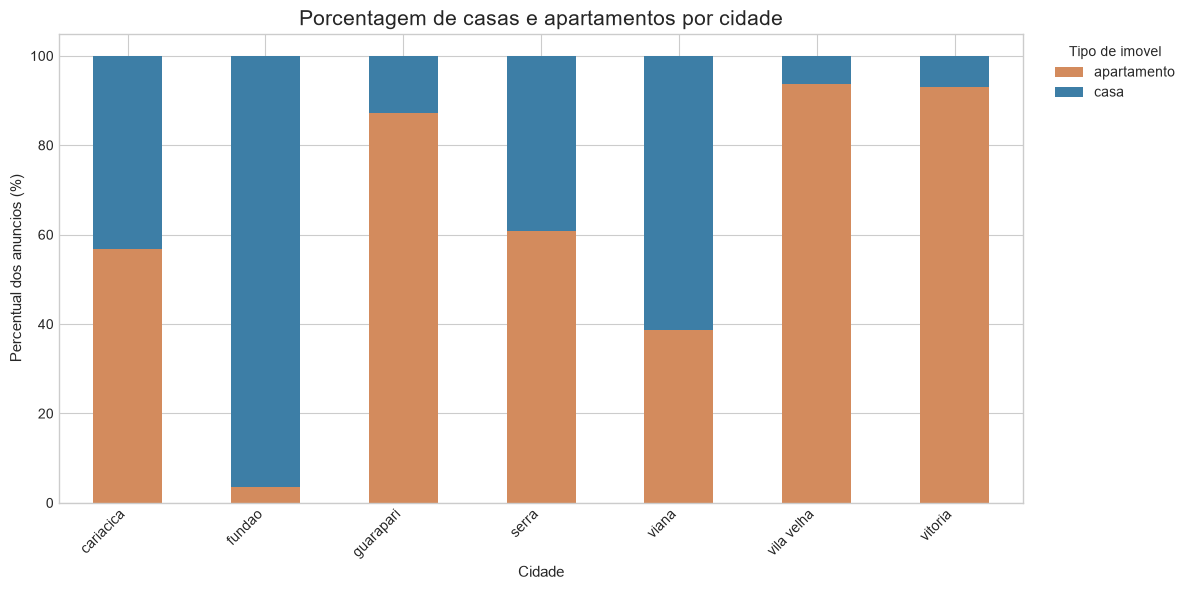

real_estate_type,apartamento,casa
city,,
cariacica,56.82,43.18
fundao,3.57,96.43
guarapari,87.31,12.69
serra,60.82,39.18
viana,38.64,61.36
vila velha,93.61,6.39
vitoria,93.10,6.90


In [37]:
house_apartment = data[data['real_estate_type'].str.lower().isin(['casa', 'apartamento'])].copy()

type_city_pct = (
    pd.crosstab(house_apartment['city'], house_apartment['real_estate_type'], normalize='index')
    .mul(100)
    .sort_index()
)

ax = type_city_pct.plot(kind='bar', stacked=True, color=['#d38b5d', '#3d7ea6'])
ax.set_title('Porcentagem de casas e apartamentos por cidade')
ax.set_xlabel('Cidade')
ax.set_ylabel('Percentual dos anuncios (%)')
ax.legend(title='Tipo de imovel', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

type_city_pct.round(2)

## 6. Tamanho medio de imovel por cidade

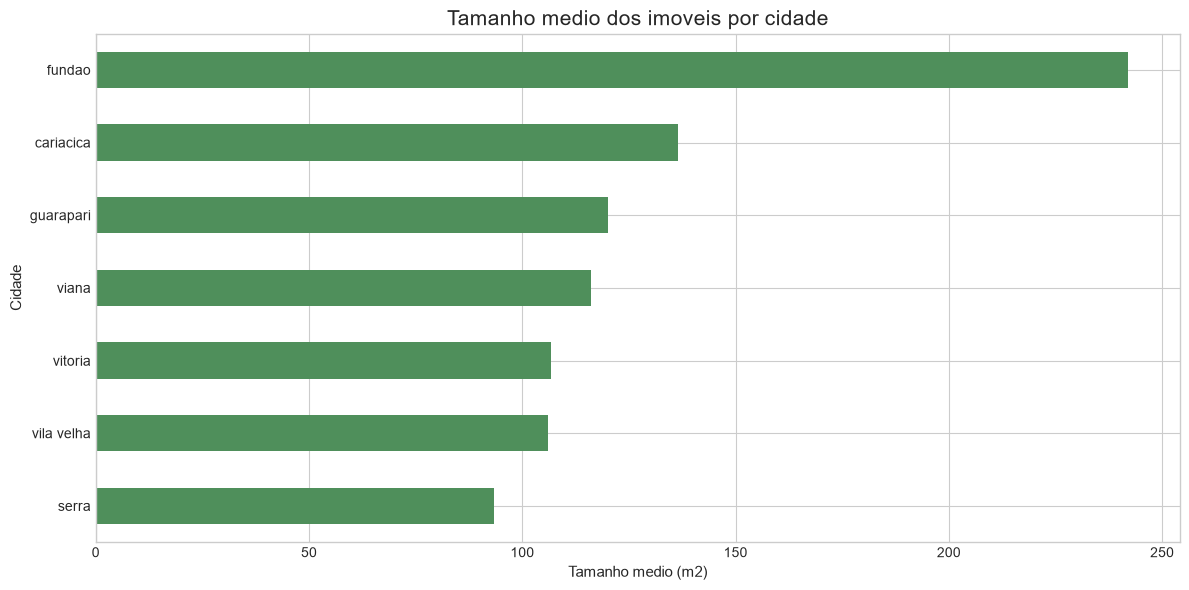

,tamanho_medio_m2
city,
serra,93.33
vila velha,106.11
vitoria,106.76
viana,116.16
guarapari,119.98
cariacica,136.60
fundao,242.09


In [38]:
avg_size_city = data.groupby('city')['size'].mean().sort_values()

ax = avg_size_city.plot(kind='barh', color='#4f8f5b')
ax.set_title('Tamanho medio dos imoveis por cidade')
ax.set_xlabel('Tamanho medio (m2)')
ax.set_ylabel('Cidade')

plt.tight_layout()
plt.show()

avg_size_city.to_frame('tamanho_medio_m2')

## 7. Preco medio do metro quadrado por cidade

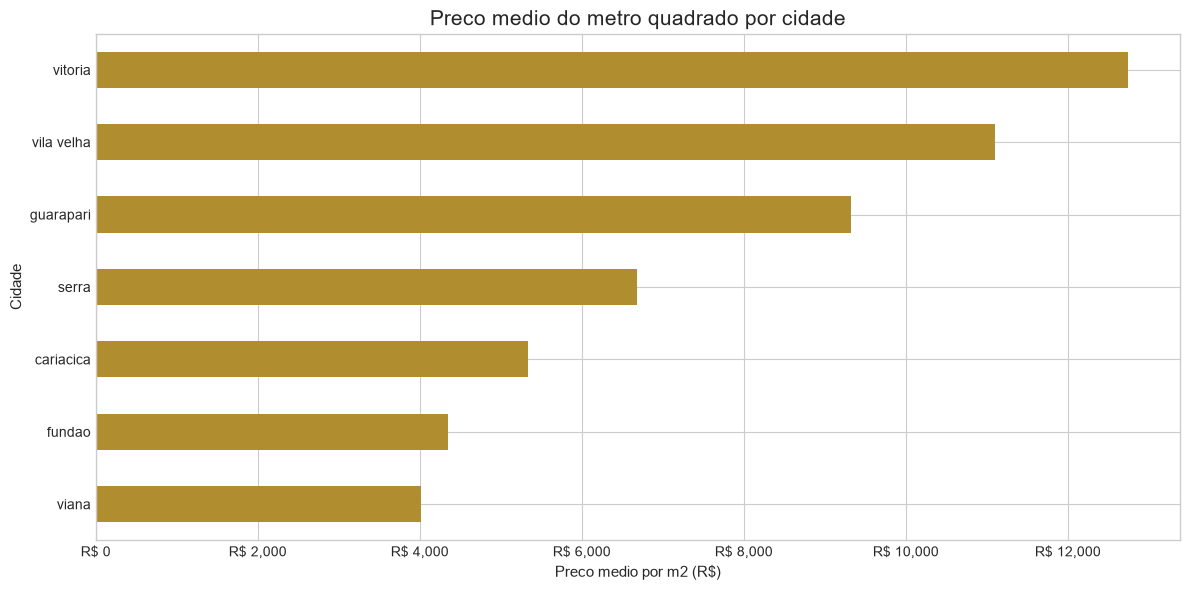

,preco_m2_medio
city,
viana,"4,015.81"
fundao,"4,345.25"
cariacica,"5,330.56"
serra,"6,683.66"
guarapari,"9,326.66"
vila velha,"11,096.66"
vitoria,"12,746.43"


In [39]:
avg_price_m2_city = data.groupby('city')['price_m2'].mean().sort_values()

ax = avg_price_m2_city.plot(kind='barh', color='#b08d2f')
ax.set_title('Preco medio do metro quadrado por cidade')
ax.set_xlabel('Preco medio por m2 (R$)')
ax.set_ylabel('Cidade')
ax.xaxis.set_major_formatter(lambda x, pos: f'R$ {x:,.0f}')

plt.tight_layout()
plt.show()

avg_price_m2_city.to_frame('preco_m2_medio')

## 8. Estatisticas dos valores dos imoveis por cidade

In [40]:
price_stats_city = (
    data.groupby('city')['price']
    .agg(
        quantidade='count',
        minimo='min',
        media='mean',
        mediana='median',
        maximo='max',
        variancia='var',
        desvio_padrao='std'
    )
    .sort_values('quantidade', ascending=False)
)

price_stats_city

,quantidade,minimo,media,mediana,maximo,variancia,desvio_padrao
city,,,,,,,
guarapari,4683,"170,000.00","1,060,834.51","875,000.00","6,980,000.00","420,628,367,183.49","648,558.68"
vila velha,4536,"130,000.00","1,140,088.52","900,000.00","9,000,333.00","607,568,422,312.93","779,466.76"
vitoria,4269,"120,000.00","1,340,406.04","1,080,000.00","8,775,000.00","833,595,893,016.45","913,014.73"
serra,3503,"140,000.00","626,222.32","430,000.00","10,000,000.00","323,966,535,020.30","569,180.58"
cariacica,628,"120,000.00","622,103.11","460,000.00","2,800,000.00","168,906,059,706.34","410,981.82"
fundao,56,"198,000.00","926,802.68","725,000.00","1,800,000.00","202,472,573,129.06","449,969.52"
viana,44,"200,000.00","401,829.55","350,000.00","920,000.00","41,656,236,548.63","204,098.60"


## 9. Variancia e desvio padrao

,quantidade,media,mediana,variancia,desvio_padrao
city,,,,,
guarapari,4683,"1,060,834.51","875,000.00","420,628,367,183.49","648,558.68"
vila velha,4536,"1,140,088.52","900,000.00","607,568,422,312.93","779,466.76"
vitoria,4269,"1,340,406.04","1,080,000.00","833,595,893,016.45","913,014.73"
serra,3503,"626,222.32","430,000.00","323,966,535,020.30","569,180.58"
cariacica,628,"622,103.11","460,000.00","168,906,059,706.34","410,981.82"
fundao,56,"926,802.68","725,000.00","202,472,573,129.06","449,969.52"
viana,44,"401,829.55","350,000.00","41,656,236,548.63","204,098.60"


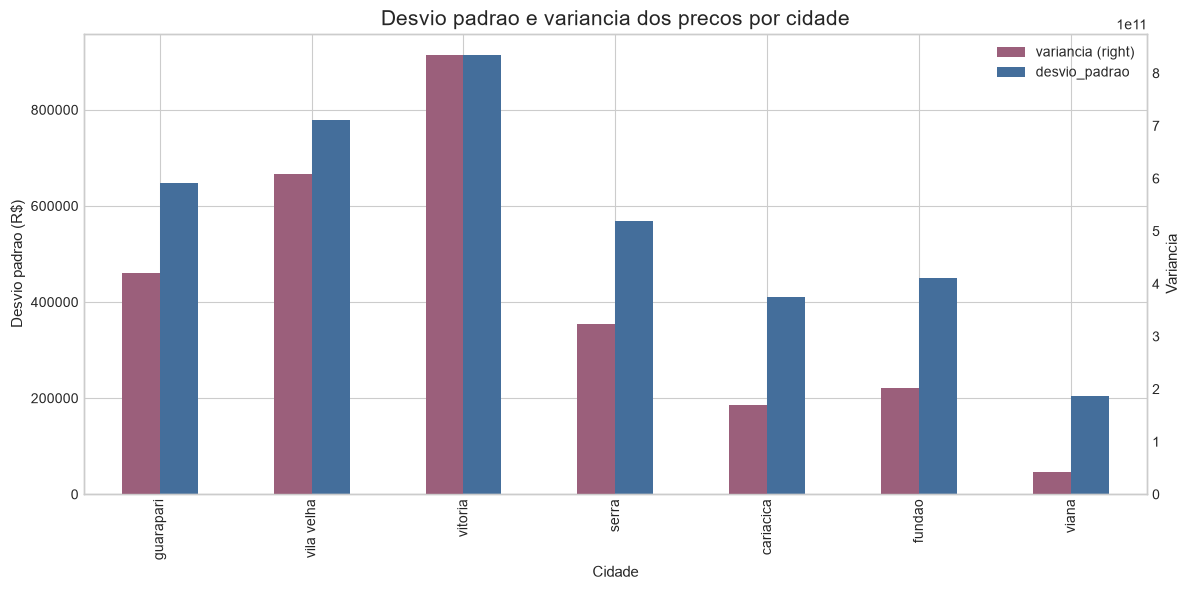

In [41]:
top10_cities = city_counts.head(10).index
top10_stats = price_stats_city.loc[top10_cities, ['quantidade', 'media', 'mediana', 'variancia', 'desvio_padrao']]

display(top10_stats)

ax = top10_stats[['variancia', 'desvio_padrao']].plot(kind='bar', secondary_y='variancia', color=['#9b5f7b', '#446e9b'])
ax.set_title('Desvio padrao e variancia dos precos por cidade')
ax.set_xlabel('Cidade')
ax.set_ylabel('Desvio padrao (R$)')
ax.right_ax.set_ylabel('Variancia')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 10. Analises extras para apoiar o modelo de previsao

### 10.1 Outliers de preco e preco por metro quadrado

Outliers podem distorcer medias e prejudicar modelos. Esta visao ajuda a decidir se vale aplicar tratamento, winsorizacao, transformacao logaritmica ou filtros.

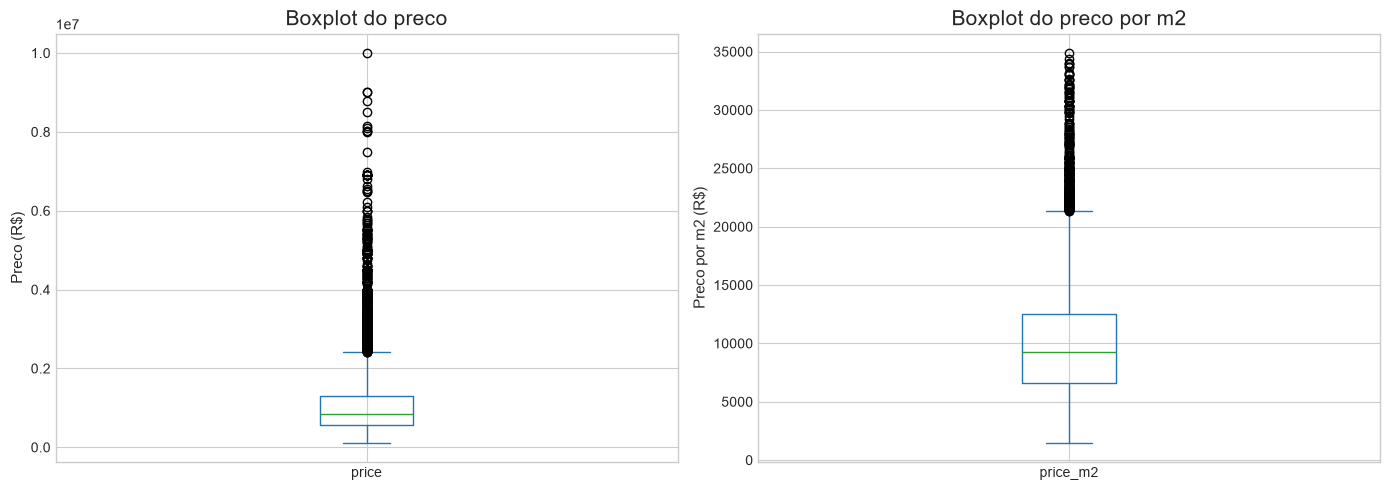

,price,price_m2,size
0.01,"220,000.00","2,500.00",38.00
0.05,"290,000.00","3,939.45",46.00
0.25,"559,000.50","6,590.91",65.00
0.50,"850,000.00","9,250.00",90.00
0.75,"1,300,000.00","12,500.00",128.00
0.95,"2,500,000.00","18,000.00",243.00
0.99,"3,900,182.66","23,529.41",377.82


In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

data['price'].dropna().plot(kind='box', ax=axes[0])
axes[0].set_title('Boxplot do preco')
axes[0].set_ylabel('Preco (R$)')

data['price_m2'].dropna().plot(kind='box', ax=axes[1])
axes[1].set_title('Boxplot do preco por m2')
axes[1].set_ylabel('Preco por m2 (R$)')

plt.tight_layout()
plt.show()

data[['price', 'price_m2', 'size']].quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])

### 10.2 Relacao entre tamanho e preco

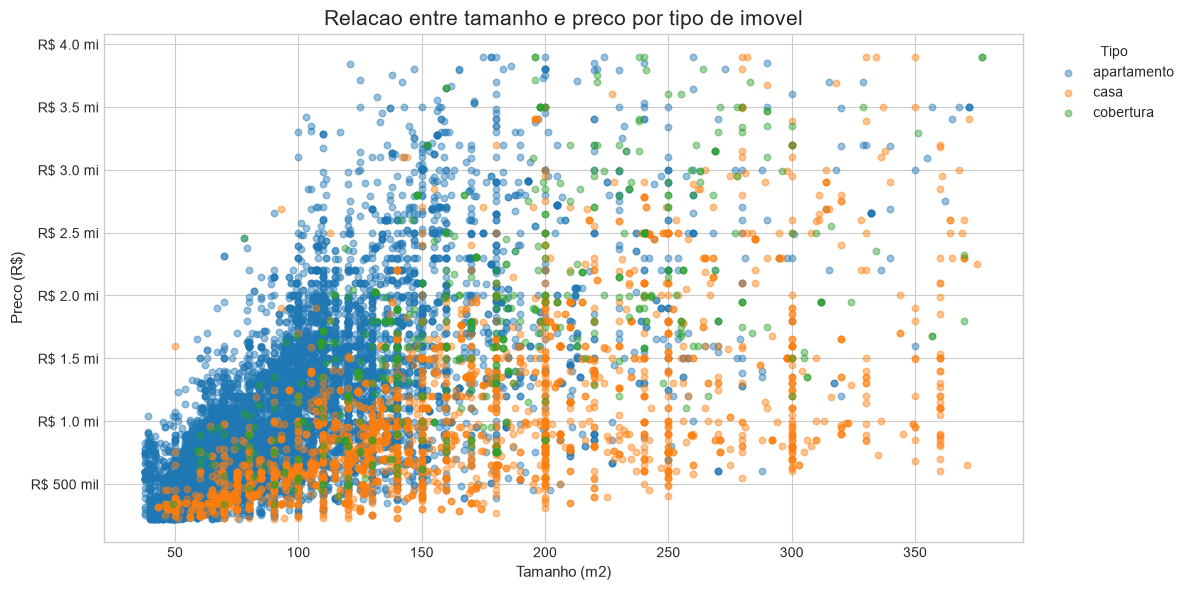

In [43]:
plot_df = data[['size', 'price', 'real_estate_type']].dropna().copy()
plot_df = plot_df[(plot_df['size'] > 0) & (plot_df['price'] > 0)]

# Limita aos percentis 1 e 99 para o grafico ficar legivel sem apagar os dados originais.
size_low, size_high = plot_df['size'].quantile([0.01, 0.99])
price_low, price_high = plot_df['price'].quantile([0.01, 0.99])
plot_df_viz = plot_df[
    plot_df['size'].between(size_low, size_high)
    & plot_df['price'].between(price_low, price_high)
]

fig, ax = plt.subplots(figsize=(12, 6))
for real_type, group in plot_df_viz.groupby('real_estate_type'):
    ax.scatter(group['size'], group['price'], alpha=0.45, s=22, label=real_type)

ax.set_title('Relacao entre tamanho e preco por tipo de imovel')
ax.set_xlabel('Tamanho (m2)')
ax.set_ylabel('Preco (R$)')
ax.yaxis.set_major_formatter(lambda x, pos: f'R$ {x/1_000_000:.1f} mi' if x >= 1_000_000 else f'R$ {x/1_000:.0f} mil')
ax.legend(title='Tipo', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 10.3 Correlacao entre variaveis numericas

Esta tabela ajuda a identificar variaveis candidatas para o modelo e possiveis redundancias.

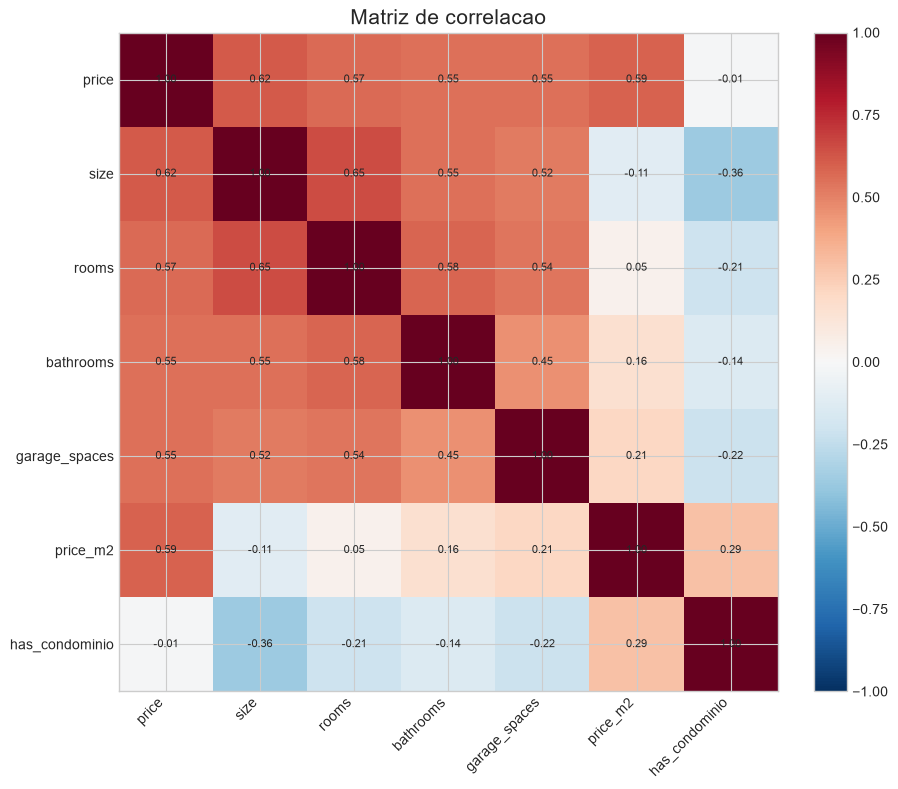

,correlacao_com_preco
price,1.00
size,0.62
price_m2,0.59
rooms,0.57
garage_spaces,0.55
bathrooms,0.55
has_condominio,-0.01


In [44]:
candidate_numeric = [
    'price', 'size', 'rooms', 'bathrooms', 'garage_spaces',
    'condominio', 'iptu', 'image_count', 'price_m2',
    'is_apartment', 'has_condominio', 'has_iptu'
]
candidate_numeric = [col for col in candidate_numeric if col in data.columns]

corr = data[candidate_numeric].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.index)))
ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticklabels(corr.index)

for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        value = corr.iloc[i, j]
        if pd.notna(value):
            ax.text(j, i, f'{value:.2f}', ha='center', va='center', fontsize=8)

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_title('Matriz de correlacao')
plt.tight_layout()
plt.show()

corr['price'].sort_values(ascending=False).to_frame('correlacao_com_preco')

### 10.4 Bairros com mais anuncios e maior preco medio por m2

Bairro costuma ser uma variavel muito forte em modelos de preco. A tabela abaixo filtra bairros com pelo menos 10 anuncios para reduzir ruido.

quantidade  preco_medio  preco_m2_medio  \
city       neighbourhood                                                  
vitoria    ilha de santa maria          21 2,484,450.00       18,283.82   
           enseada do sua              249 2,042,383.15       18,249.31   
           praia do canto              383 1,940,037.74       16,207.64   
vila velha darly santos                 15 2,228,326.67       14,804.15   
vitoria    mata da praia               237 2,074,910.80       14,643.37   
           santa helena                 82 1,310,653.59       13,739.14   
           aeroporto                    12   958,320.75       13,567.65   
           barro vermelho              139 1,411,370.30       13,414.46   
vila velha praia de itaparica         1278 1,117,895.83       12,900.91   
vitoria    praia do sua                 77   979,495.84       12,872.17   
           santa luiza                  26 1,251,407.23       12,549.56   
           jardim camburi             1750 1,143,245.17       12,428.50   
           santa lucia                 155 1,191,091.08       12,423.85   
vila velha jardim guaranhuns            12   841,075.00       12,204.84   
vitoria    monte belo                   16 1,311,748.25       12,010.09   
vila velha sao conrado                  42   797,939.88       11,827.61   
           jockey de itaparica         165   995,114.85       11,729.30   
guarapari  enseada azul                465 1,407,859.49       11,691.62   
vitoria    morada de camburi            13 1,335,164.54       11,633.73   
vila velha praia da costa             1129 1,477,304.35       11,508.54   

                                tamanho_medio  
city       neighbourhood                       
vitoria    ilha de santa maria         136.19  
           enseada do sua              110.59  
           praia do canto              120.97  
vila velha darly santos                150.53  
vitoria    mata da praia               145.43  
           santa helena                105.24  
           aeroporto                    71.00  
           barro vermelho              101.45  
vila velha praia de itaparica           87.20  
vitoria    praia do sua                 82.31  
           santa luiza                 102.15  
           jardim camburi               92.57  
           santa lucia                  98.81  
vila velha jardim guaranhuns            68.67  
vitoria    monte belo                  112.88  
vila velha sao conrado                  73.83  
           jockey de itaparica          79.01  
guarapari  enseada azul                119.64  
vitoria    morada de camburi           121.08  
vila velha praia da costa              132.80

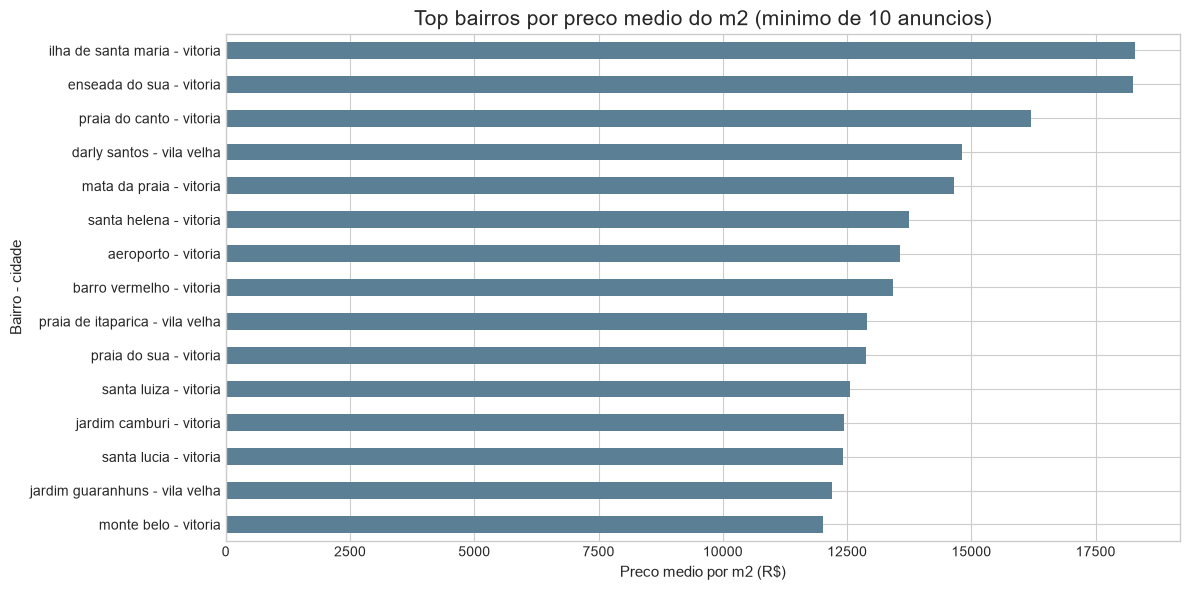

In [45]:
neighbourhood_stats = (
    data.groupby(['city', 'neighbourhood'], dropna=False)
    .agg(
        quantidade=('price', 'count'),
        preco_medio=('price', 'mean'),
        preco_m2_medio=('price_m2', 'mean'),
        tamanho_medio=('size', 'mean')
    )
    .query('quantidade >= 10')
    .sort_values('preco_m2_medio', ascending=False)
)

display(neighbourhood_stats.head(20))

top_neighbourhoods = neighbourhood_stats.head(15).sort_values('preco_m2_medio')
labels = [f'{bairro} - {cidade}' for cidade, bairro in top_neighbourhoods.index]

ax = top_neighbourhoods['preco_m2_medio'].plot(kind='barh', color='#5b7f95')
ax.set_title('Top bairros por preco medio do m2 (minimo de 10 anuncios)')
ax.set_xlabel('Preco medio por m2 (R$)')
ax.set_ylabel('Bairro - cidade')
ax.set_yticklabels(labels)
plt.tight_layout()
plt.show()

## 11. Insights para a etapa de modelagem

- Use `price` como alvo e evite usar `price_m2` como variavel explicativa se ele foi calculado a partir de `price`, pois isso gera vazamento de dados.
- Cidade, bairro e tipo de imovel devem ser variaveis categoricas importantes.
- Tamanho, quartos, banheiros, vagas, condominio, IPTU e quantidade de imagens tendem a ser boas candidatas numericas.
- Analise outliers antes do treino. Uma opcao e treinar com `log1p(price)` para reduzir assimetria.
- Separe treino e teste antes de fazer transformacoes aprendidas nos dados, como encoding e imputacao.